# Cervical transformation zone type classification

This notebook classifies colposcopy images of the cervix into transformation
zone Type 1, Type 2 or Type 3. It uses the Intel & MobileODT Cervical Cancer
Screening data from Kaggle, plus about 6,500 extra images that I cleaned and
added to the training set.

**Method.** Three EfficientNet models (B0 at 256 px, B0 at 384 px and B2 at
288 px) are fine-tuned with transfer learning. Their softmax outputs are
averaged, and temperature scaling (T = 0.803) is applied so that the predicted
probabilities are better calibrated.

**What the notebook does.** It trains the models, evaluates the ensemble once
on a held-out test split of 222 images, and reports accuracy, log loss, AUC,
calibration and Grad-CAM heatmaps with bootstrap 95% confidence intervals.
It also checks for near-duplicate images between the training and test sets,
and compares the result with a baseline trained without the extra images.

**Limitations.** The split is by image, not by patient. The labels in this
dataset are noisy. This is a research project and not a medical device.

**Attach as inputs:** competition `intel-mobileodt-cervical-cancer-screening`
and dataset `cervical-prepared` (holds `splits_relative.csv`).
Accelerator: GPU T4.

In [1]:
import os, glob, copy, time, json, hashlib, zipfile, shutil, math, random, subprocess, sys
from collections import Counter
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision import models
from sklearn.metrics import (log_loss, accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

assert torch.cuda.is_available(), "No GPU: Settings > Accelerator > GPU T4, then run this cell again"
dev = "cuda"
OUT = "/kaggle/working"
classes = ["Type_1", "Type_2", "Type_3"]
cls2idx = {c: i for i, c in enumerate(classes)}
L = [0, 1, 2]
BS = 32
norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

print("cuda:", torch.cuda.get_device_name(0))

cuda: Tesla T4


Statistics helpers (numpy only). `ci_table` gives a 95% bootstrap interval for any metric function.

In [33]:
def apply_T(P, t):
    z = np.log(np.clip(P, 1e-8, 1)) / t
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def ece(P, y, bins=10):
    conf, pred = P.max(1), P.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    tot = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            tot += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return tot

NAMES = ["logloss", "accuracy", "Type_1 recall", "Type_2 recall", "Type_3 recall", "macro AUC"]
def metrics(P, y):
    pred = P.argmax(1)
    rec = [((pred == k) & (y == k)).sum() / (y == k).sum() for k in L]
    return [log_loss(y, P, labels=L), accuracy_score(y, pred), *rec,
            roc_auc_score(y, P, multi_class="ovr")]

def bootstrap(P, y, fn, B=2000, seed=42):
    rng = np.random.default_rng(seed)
    n, out = len(y), []
    for _ in range(B):
        i = rng.integers(0, n, n)
        if len(np.unique(y[i])) < 3:      # a resample missing a class cannot be scored
            continue
        out.append(fn(P[i], y[i]))
    return np.array(out)

def ci_table(P, y, fn, names, B=2000):
    boot, point = bootstrap(P, y, fn, B), fn(P, y)
    rows = []
    for j, nm in enumerate(names):
        lo, hi = np.percentile(boot[:, j], [2.5, 97.5])
        rows.append(dict(measure=nm, value=round(point[j], 3), ci_low=round(lo, 3), ci_high=round(hi, 3)))
    return pd.DataFrame(rows)

def to_u64(hs):
    return np.array([int(h, 16) for h in hs], dtype=np.uint64)

def ham(a, b):
    x = np.ascontiguousarray(np.bitwise_xor(a[:, None], b[None, :]))
    return np.unpackbits(x.view(np.uint8).reshape(x.shape + (8,)), axis=-1).sum(-1)

Model code (data, networks, training), defined once. `train()` takes everything as arguments and saves `val_probs_<name>.npy` for every run.

In [3]:
class PadSquare:
    def __call__(self, im):
        w, h = im.size
        s = max(w, h)
        c = Image.new("RGB", (s, s), (0, 0, 0))
        c.paste(im, ((s - w) // 2, (s - h) // 2))
        return c

def make_tf(size, train=False):
    aug = [T.RandomHorizontalFlip(), T.RandomRotation(15), T.ColorJitter(0.2, 0.2, 0.1)] if train else []
    return T.Compose([PadSquare(), T.Resize((size, size))] + aug + [T.ToTensor(), norm])

class CervixDS(Dataset):
    def __init__(self, d, tf):
        self.paths, self.tf = d["path"].tolist(), tf
        self.y = d["label"].map(cls2idx).tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return self.tf(im.convert("RGB")), self.y[i]

def loader(d, size, train=False):
    return DataLoader(CervixDS(d, make_tf(size, train)), BS, shuffle=train, num_workers=4)

ARCH = {"efficientnet_b0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.DEFAULT),
        "efficientnet_b2": (models.efficientnet_b2, models.EfficientNet_B2_Weights.DEFAULT)}

def build(arch, pretrained=False):
    fn, w = ARCH[arch]
    m = fn(weights=w if pretrained else None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 3)
    return m.to(dev)

@torch.no_grad()
def predict(m, dl):
    m.eval()
    P, Y = [], []
    for x, y in dl:
        with torch.autocast(dev):
            out = m(x.to(dev))
        P.append(torch.softmax(out.float(), 1).cpu())
        Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def train(name, arch, train_df, val_df, size, seed, lr=3e-4, epochs=20, patience=5,
          use_class_weights=True, force=False):
    """Train (or load, if <name>.pt exists) and save val probabilities. Validation is used only for early stopping."""
    set_seed(seed)
    wpath = f"{OUT}/{name}.pt"
    loading = os.path.exists(wpath) and not force
    m = build(arch, pretrained=not loading)
    val_dl = loader(val_df, size)
    if loading:
        print(f"{name}: found {wpath}, loading instead of retraining")
        m.load_state_dict(torch.load(wpath, map_location=dev))
    else:
        train_dl = loader(train_df, size, train=True)
        counts = train_df["label"].value_counts().reindex(classes).values
        w = torch.tensor(len(train_df) / (3 * counts), dtype=torch.float32) if use_class_weights else torch.ones(3)
        print(f"{name}: class weights", w.round(decimals=3).tolist())
        crit = nn.CrossEntropyLoss(weight=w.to(dev), label_smoothing=0.1)
        opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
        scaler = torch.amp.GradScaler()
        best, best_state, wait, n = 9.0, None, 0, len(train_df)
        for ep in range(epochs):
            m.train(); t, tl = time.time(), 0.0
            for x, y in train_dl:
                x, y = x.to(dev), y.to(dev)
                opt.zero_grad()
                with torch.autocast(dev):
                    loss = crit(m(x), y)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update()
                tl += loss.item() * len(y)
            sched.step()
            P, Y = predict(m, val_dl)
            vl, acc = log_loss(Y, P, labels=L), accuracy_score(Y, P.argmax(1))
            print(f"ep {ep+1:2d} | train {tl/n:.3f} | val logloss {vl:.3f} acc {acc:.3f} | {time.time()-t:.0f}s")
            if vl < best:
                best, best_state, wait = vl, copy.deepcopy(m.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    print("early stop"); break
        m.load_state_dict(best_state)
        torch.save(best_state, wpath)
        print("best val logloss:", round(best, 3))
    P, _ = predict(m, val_dl)
    np.save(f"{OUT}/val_probs_{name}.npy", P)
    return m

## Part 1: resize the training images to 384 px

Only needed once. Skip it if `cervical-prepared` already contains `dataset_small`. The known truncated file `Type_1/1339.jpg` is expected to be the one error.

In [4]:
paths = glob.glob("/kaggle/input/**/Type_*/*.jpg", recursive=True)
train_paths = [p for p in paths if "/train/" in p]
print(len(train_paths), "train images", dict(Counter(p.split("/")[-2] for p in train_paths)))
assert train_paths, "no training images found: is the competition attached?"

SIZE, SMALL, errors = 384, f"{OUT}/dataset_small", []
for p in tqdm(train_paths):
    out = os.path.join(SMALL, p.split("/")[-2], os.path.basename(p))
    os.makedirs(os.path.dirname(out), exist_ok=True)
    try:
        with Image.open(p) as im:
            im = im.convert("RGB")
            im.thumbnail((SIZE, SIZE))
            im.save(out, quality=92)
    except Exception as e:
        errors.append(f"{p}: {e}")
print("errors:", len(errors), errors[:3])

n = sum(len(f) for _, _, f in os.walk(SMALL))
shutil.make_archive(f"{OUT}/dataset_small", "zip", SMALL)
print(n, "images saved |", round(os.path.getsize(f"{OUT}/dataset_small.zip") / 1e6, 1), "MB")

1481 train images {'Type_2': 781, 'Type_3': 450, 'Type_1': 250}


100%|██████████| 1481/1481 [04:41<00:00,  5.26it/s]


errors: 1 ['/kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening/train/train/Type_1/1339.jpg: image file is truncated (53 bytes not processed)']
1480 images saved | 28.5 MB


## Part 2: data, baseline, extra images, near-duplicate check

Expected: split table train 1036, val 222, test 222 and `all files exist: True`.

In [5]:
csv = glob.glob("/kaggle/input/**/splits_relative.csv", recursive=True)[0]
root = os.path.dirname(csv)
zips = glob.glob(root + "/**/dataset_small.zip", recursive=True)
if zips:
    zipfile.ZipFile(zips[0]).extractall("/tmp/data")
    base = "/tmp/data"
else:
    base = root
img_dir = os.path.dirname(glob.glob(base + "/**/Type_1", recursive=True)[0])

main = pd.read_csv(csv)
main["path"] = main["file"].apply(lambda f: os.path.join(img_dir, f))
assert main["file"].is_unique, "a file appears twice in splits_relative.csv"
print(pd.crosstab(main["label"], main["split"], margins=True))
print("all files exist:", all(os.path.exists(p) for p in main["path"]))
tr0, va, te = [main[main["split"] == s] for s in ("train", "val", "test")]

split   test  train  val   All
label                         
Type_1    38    174   37   249
Type_2   117    547  117   781
Type_3    67    315   68   450
All      222   1036  222  1480
all files exist: True


Baseline: the original 1,036 training images only, same settings as run A. This is the reference for "do the extra images help?".

In [6]:
model_e1 = train("e1_baseline", "efficientnet_b0", tr0, va, 256, seed=42)
P, Y = predict(model_e1, loader(va, 256))
print(classification_report(Y, P.argmax(1), target_names=classes, digits=3))
print(confusion_matrix(Y, P.argmax(1)))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


e1_baseline: class weights [1.9850000143051147, 0.6309999823570251, 1.0959999561309814]
ep  1 | train 1.044 | val logloss 0.928 acc 0.536 | 54s
ep  2 | train 0.888 | val logloss 0.861 acc 0.599 | 5s
ep  3 | train 0.779 | val logloss 0.895 acc 0.631 | 5s
ep  4 | train 0.701 | val logloss 0.929 acc 0.595 | 5s
ep  5 | train 0.645 | val logloss 0.973 acc 0.608 | 5s
ep  6 | train 0.571 | val logloss 1.055 acc 0.572 | 5s
ep  7 | train 0.544 | val logloss 1.118 acc 0.532 | 5s
early stop
best val logloss: 0.861
              precision    recall  f1-score   support

      Type_1      0.368     0.378     0.373        37
      Type_2      0.680     0.598     0.636       117
      Type_3      0.605     0.721     0.658        68

    accuracy                          0.599       222
   macro avg      0.551     0.566     0.556       222
weighted avg      0.605     0.599     0.599       222

[[14 18  5]
 [20 70 27]
 [ 4 15 49]]


Extra images. The additional folders already carry the corrected labels, so nothing is relabelled; the code only checks this and drops the files on the removal list.

In [7]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imagehash"], check=True)
import imagehash
from concurrent.futures import ThreadPoolExecutor

comp = "/kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening"
rows = [{"src": p, "filename": os.path.basename(p), "label": p.split("/")[-2]}
        for p in glob.glob(comp + "/additional_Type_*_v2/Type_*/*.jpg")]
allx = pd.DataFrame(rows)
fixed = pd.read_csv(comp + "/fixed_labels_v2.csv")
removed = pd.read_csv(comp + "/removed_files.csv")

print(len(allx), "extra images", dict(Counter(allx["label"])))
fixed["key_new"] = fixed["filename"] + "|" + fixed["new_label"]
allx["key_new"] = allx["filename"] + "|" + allx["label"]
n_fixed = int(fixed["key_new"].isin(allx["key_new"]).sum())
print("fixed labels already applied in folders:", n_fixed, "of", len(fixed))
if n_fixed < len(fixed):
    print("WARNING: some corrected labels are not in the folders; those images keep their old label")
print("removal-list files present:", int(removed["filename"].isin(allx["filename"]).sum()), "of", len(removed))

ex = allx[~allx["filename"].isin(removed["filename"])].copy()
ex["final"] = ex["label"]
print(len(ex), "kept |", dict(ex["final"].value_counts()))

6734 extra images {'Type_3': 1976, 'Type_1': 1191, 'Type_2': 3567}
fixed labels already applied in folders: 1821 of 1821
removal-list files present: 6 of 197
6728 kept | {'Type_2': np.int64(3565), 'Type_3': np.int64(1974), 'Type_1': np.int64(1189)}


In [8]:
EXTRA = f"{OUT}/extra_small"
shutil.rmtree(EXTRA, ignore_errors=True)

def proc(r):
    out = os.path.join(EXTRA, r.final, "x_" + r.filename)
    os.makedirs(os.path.dirname(out), exist_ok=True)
    try:
        with Image.open(r.src) as im:
            im = im.convert("RGB")
            im.thumbnail((SIZE, SIZE))
            im.save(out, quality=92)
            h = str(imagehash.phash(im))
        return out, h, None
    except Exception as e:
        return out, None, f"{r.src}: {e}"

with ThreadPoolExecutor(4) as pool:
    res = list(tqdm(pool.map(proc, ex.itertuples()), total=len(ex)))
ex["out"], ex["phash"] = [r[0] for r in res], [r[1] for r in res]
errs = [r[2] for r in res if r[2]]
print("errors:", len(errs), errs[:3])
ex = ex[ex["phash"].notna()].reset_index(drop=True)
print(len(ex), "images saved")

100%|██████████| 6728/6728 [07:19<00:00, 15.29it/s]

errors: 5 ['/kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening/additional_Type_1_v2/Type_1/3068.jpg: image file is truncated (107 bytes not processed)', "/kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening/additional_Type_1_v2/Type_1/5893.jpg: cannot identify image file '/kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening/additional_Type_1_v2/Type_1/5893.jpg'", "/kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening/additional_Type_2_v2/Type_2/2845.jpg: cannot identify image file '/kaggle/input/competitions/intel-mobileodt-cervical-cancer-screening/additional_Type_2_v2/Type_2/2845.jpg'"]
6723 images saved


Near-duplicate check with perceptual hashes (Hamming distance on 64 bits; 0 = identical). Two questions: (a) which extra images are too close to val/test, and (b) which val/test images are too close to the training images. (b) is saved to `leak_table.csv` and used again in Step 49.

Expected: no exact duplicates in the main split (distance 0 row near zero); the printed table shows how fast the counts grow with the threshold.

In [9]:
hashes = []
for p in tqdm(main["path"]):
    with Image.open(p) as im:
        hashes.append(str(imagehash.phash(im)))
main["phash"] = hashes

hs, he = to_u64(main["phash"]), to_u64(ex["phash"])
is_tr = (main["split"] == "train").values
d_ex = ham(he, hs[~is_tr]).min(1)        # each extra image -> nearest val/test image
d_vt = ham(hs[~is_tr], hs[is_tr]).min(1)  # each val/test image -> nearest training image

print("dist | extras close to val/test | val/test close to original train")
for t in [0, 2, 4, 6, 8, 10, 12]:
    print(f"<= {t:2d} | {int((d_ex <= t).sum()):6d} | {int((d_vt <= t).sum()):4d} of {len(d_vt)}")

leak = main.loc[~is_tr, ["file", "split"]].copy()
leak["d_train"] = d_vt
leak.to_csv(f"{OUT}/leak_table.csv", index=False)

100%|██████████| 1480/1480 [00:23<00:00, 61.71it/s] 


dist | extras close to val/test | val/test close to original train
<=  0 |     15 |    0 of 444
<=  2 |     41 |    0 of 444
<=  4 |     67 |    0 of 444
<=  6 |     94 |    0 of 444
<=  8 |    127 |    3 of 444
<= 10 |    234 |   17 of 444
<= 12 |    613 |   53 of 444


In [10]:
THRESH = 10
keep = d_ex > THRESH
print("removed as near-duplicates of val/test:", int((~keep).sum()), "| kept:", int(keep.sum()))

ec = ex[keep].copy()
ec["file"] = ec["final"] + "/" + ec["out"].apply(os.path.basename)
ec[["file", "final", "phash"]].rename(columns={"final": "label"}).to_csv(f"{OUT}/extra_relative.csv", index=False)

keep_names, deleted = set(ec["out"]), 0
for r_, _, fs_ in os.walk(EXTRA):
    for f in fs_:
        p = os.path.join(r_, f)
        if p not in keep_names:
            os.remove(p); deleted += 1
print("files deleted from folder:", deleted)

shutil.make_archive(EXTRA, "zip", EXTRA)
print(round(os.path.getsize(EXTRA + ".zip") / 1e6, 1), "MB")
print(dict(ec["final"].value_counts()))

removed as near-duplicates of val/test: 234 | kept: 6489
files deleted from folder: 234
122.6 MB
{'Type_2': np.int64(3431), 'Type_3': np.int64(1915), 'Type_1': np.int64(1143)}


## Part 3: final training, ensemble, validation analysis

Training set = 1,036 original + the cleaned extra images. Validation and test contain **original images only**. Expected: train about 7,525 images; every run below skips training if its `.pt` file is already in `/kaggle/working`.

In [11]:
extra = pd.read_csv(f"{OUT}/extra_relative.csv")
extra["path"] = extra["file"].apply(lambda f: os.path.join(EXTRA, f))
tr = pd.concat([tr0[["path", "label"]], extra[["path", "label"]]], ignore_index=True)
print("train:", len(tr), tr["label"].value_counts().to_dict(), "| val:", len(va), "| test:", len(te))
print("all files exist:", all(os.path.exists(p) for p in tr["path"]))

# class frequencies of the training set, saved for the reference baseline in Step 46
prior = tr["label"].map(cls2idx).value_counts(normalize=True).sort_index().values
np.save(f"{OUT}/train_prior.npy", prior)

train: 7525 {'Type_2': 3978, 'Type_3': 2230, 'Type_1': 1317} | val: 222 | test: 222
all files exist: True


In [12]:
model_A = train("e2_b0_extra",     "efficientnet_b0", tr, va, 256, seed=42)
model_B = train("e3_b0_384_extra", "efficientnet_b0", tr, va, 384, seed=7)
model_C = train("e4_b2_288_extra", "efficientnet_b2", tr, va, 288, seed=11, lr=2e-4)

e2_b0_extra: class weights [1.9049999713897705, 0.6309999823570251, 1.125]
ep  1 | train 1.013 | val logloss 0.901 acc 0.554 | 40s
ep  2 | train 0.894 | val logloss 0.877 acc 0.613 | 29s
ep  3 | train 0.788 | val logloss 0.797 acc 0.626 | 30s
ep  4 | train 0.694 | val logloss 0.839 acc 0.626 | 30s
ep  5 | train 0.614 | val logloss 0.801 acc 0.658 | 30s
ep  6 | train 0.539 | val logloss 0.778 acc 0.676 | 30s
ep  7 | train 0.499 | val logloss 0.803 acc 0.653 | 30s
ep  8 | train 0.462 | val logloss 0.828 acc 0.680 | 30s
ep  9 | train 0.431 | val logloss 0.756 acc 0.694 | 30s
ep 10 | train 0.416 | val logloss 0.833 acc 0.662 | 30s
ep 11 | train 0.407 | val logloss 0.774 acc 0.707 | 30s
ep 12 | train 0.399 | val logloss 0.809 acc 0.694 | 30s
ep 13 | train 0.389 | val logloss 0.781 acc 0.703 | 30s
ep 14 | train 0.383 | val logloss 0.796 acc 0.694 | 29s
early stop
best val logloss: 0.756
e3_b0_384_extra: class weights [1.9049999713897705, 0.6309999823570251, 1.125]
ep  1 | train 1.017 | val l

100%|██████████| 35.2M/35.2M [00:00<00:00, 173MB/s]


e4_b2_288_extra: class weights [1.9049999713897705, 0.6309999823570251, 1.125]
ep  1 | train 1.007 | val logloss 0.885 acc 0.568 | 80s
ep  2 | train 0.857 | val logloss 0.817 acc 0.644 | 53s
ep  3 | train 0.722 | val logloss 0.836 acc 0.658 | 52s
ep  4 | train 0.622 | val logloss 0.770 acc 0.658 | 53s
ep  5 | train 0.533 | val logloss 0.819 acc 0.671 | 53s
ep  6 | train 0.487 | val logloss 0.718 acc 0.707 | 53s
ep  7 | train 0.445 | val logloss 0.814 acc 0.689 | 53s
ep  8 | train 0.429 | val logloss 0.925 acc 0.649 | 53s
ep  9 | train 0.416 | val logloss 0.838 acc 0.698 | 53s
ep 10 | train 0.404 | val logloss 0.713 acc 0.757 | 53s
ep 11 | train 0.389 | val logloss 0.737 acc 0.721 | 53s
ep 12 | train 0.383 | val logloss 0.771 acc 0.721 | 53s
ep 13 | train 0.380 | val logloss 0.796 acc 0.725 | 53s
ep 14 | train 0.373 | val logloss 0.773 acc 0.739 | 53s
ep 15 | train 0.371 | val logloss 0.766 acc 0.743 | 53s
early stop
best val logloss: 0.713


Ensemble = equal mean of the three softmax outputs. Expected (earlier run): ensemble val log loss about 0.62, accuracy about 0.74, confusion matrix close to `[[19,14,4],[6,98,13],[1,19,48]]`.

In [13]:
Y = va["label"].map(cls2idx).values
np.save(f"{OUT}/val_labels.npy", Y)
runs = {"A": "e2_b0_extra", "B": "e3_b0_384_extra", "C": "e4_b2_288_extra"}
probs = {t: np.load(f"{OUT}/val_probs_{n}.npy") for t, n in runs.items()}
Pens = (probs["A"] + probs["B"] + probs["C"]) / 3
np.save(f"{OUT}/val_probs_ens.npy", Pens)

for name, P in [("A b0 256", probs["A"]), ("B b0 384", probs["B"]), ("C b2 288", probs["C"]),
                ("avg A+B", (probs["A"] + probs["B"]) / 2), ("avg A+B+C", Pens)]:
    print(f"{name:10s} logloss {log_loss(Y, P, labels=L):.3f}  acc {accuracy_score(Y, P.argmax(1)):.3f}")
print(classification_report(Y, Pens.argmax(1), target_names=classes, digits=3))
print(confusion_matrix(Y, Pens.argmax(1)))

A b0 256   logloss 0.756  acc 0.694
B b0 384   logloss 0.740  acc 0.653
C b2 288   logloss 0.713  acc 0.757
avg A+B    logloss 0.664  acc 0.703
avg A+B+C  logloss 0.621  acc 0.743
              precision    recall  f1-score   support

      Type_1      0.731     0.514     0.603        37
      Type_2      0.748     0.838     0.790       117
      Type_3      0.738     0.706     0.722        68

    accuracy                          0.743       222
   macro avg      0.739     0.686     0.705       222
weighted avg      0.742     0.743     0.738       222

[[19 14  4]
 [ 6 98 13]
 [ 1 19 48]]


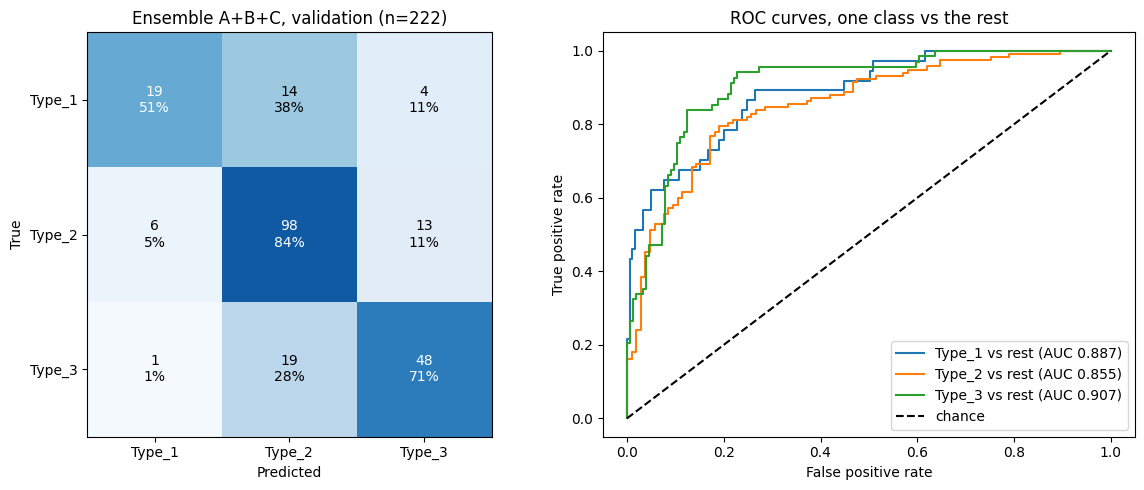

macro AUC: 0.883


In [14]:
def plot_cm_roc(P, y, title, fname):
    cm = confusion_matrix(y, P.argmax(1), labels=L)
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax[0].set_xticks(range(3)); ax[0].set_xticklabels(classes)
    ax[0].set_yticks(range(3)); ax[0].set_yticklabels(classes)
    ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True"); ax[0].set_title(title)
    for i in range(3):
        for j in range(3):
            ax[0].text(j, i, f"{cm[i, j]}\n{cmn[i, j]*100:.0f}%", ha="center", va="center",
                       color="white" if cmn[i, j] > 0.5 else "black")
    Yb = label_binarize(y, classes=L)
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Yb[:, k], P[:, k])
        ax[1].plot(fpr, tpr, label=f"{c} vs rest (AUC {auc(fpr, tpr):.3f})")
    ax[1].plot([0, 1], [0, 1], "k--", label="chance")
    ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
    ax[1].set_title("ROC curves, one class vs the rest"); ax[1].legend(loc="lower right")
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=200); plt.show()
    print("macro AUC:", round(roc_auc_score(y, P, multi_class="ovr"), 3))

plot_cm_roc(Pens, Y, f"Ensemble A+B+C, validation (n={len(Y)})", "fig_confusion_roc.png")

Confident mistakes and confident correct predictions (validation). Expected: about 57 mistakes of 222; mean confidence lower for wrong (about 0.61) than for correct (about 0.74).

mistakes: 57 of 222
mean confidence: correct 0.74 | wrong 0.61


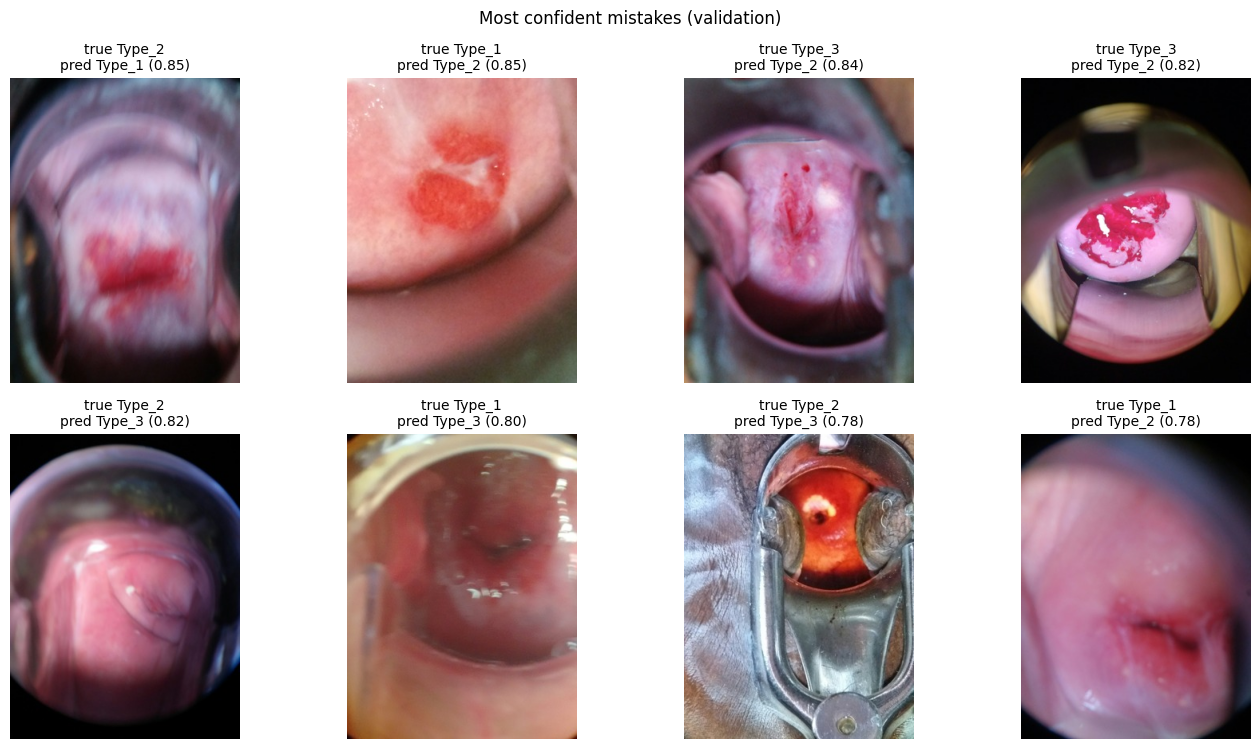

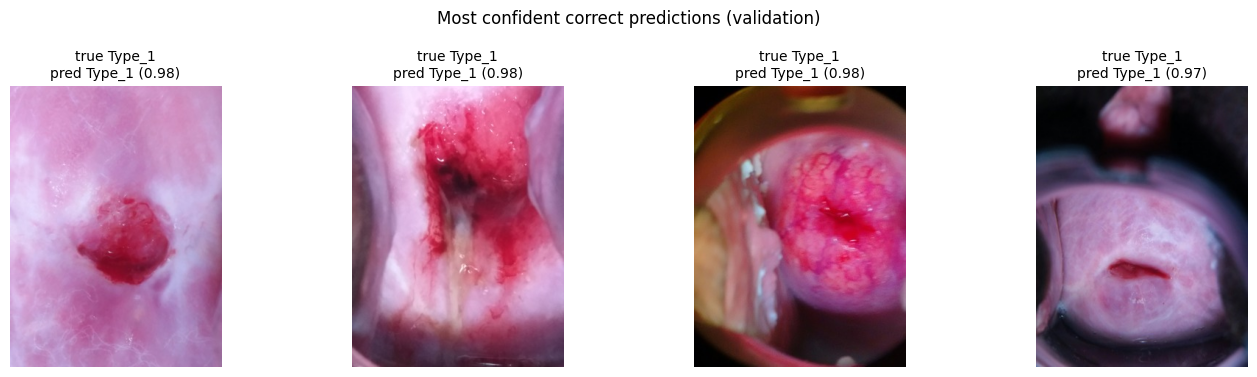

In [15]:
pred, conf = Pens.argmax(1), Pens.max(1)
wrong, right = np.where(pred != Y)[0], np.where(pred == Y)[0]
worst = wrong[np.argsort(-conf[wrong])][:8]
best = right[np.argsort(-conf[right])][:4]
print("mistakes:", len(wrong), "of", len(Y))
print(f"mean confidence: correct {conf[right].mean():.2f} | wrong {conf[wrong].mean():.2f}")

def show(idx, title, fname):
    rows = math.ceil(len(idx) / 4)
    fig, axes = plt.subplots(rows, 4, figsize=(14, 3.8 * rows))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        with Image.open(va.iloc[i]["path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"true {classes[Y[i]]}\npred {classes[pred[i]]} ({conf[i]:.2f})", fontsize=10)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=150); plt.show()

show(worst, "Most confident mistakes (validation)", "fig_confident_mistakes.png")
show(best, "Most confident correct predictions (validation)", "fig_confident_correct.png")

Grad-CAM on model C. The images are chosen with the ensemble, the heat map comes from model C alone, so the title shows what model C itself predicted. Look for heat on the cervix, not on the border or speculum.

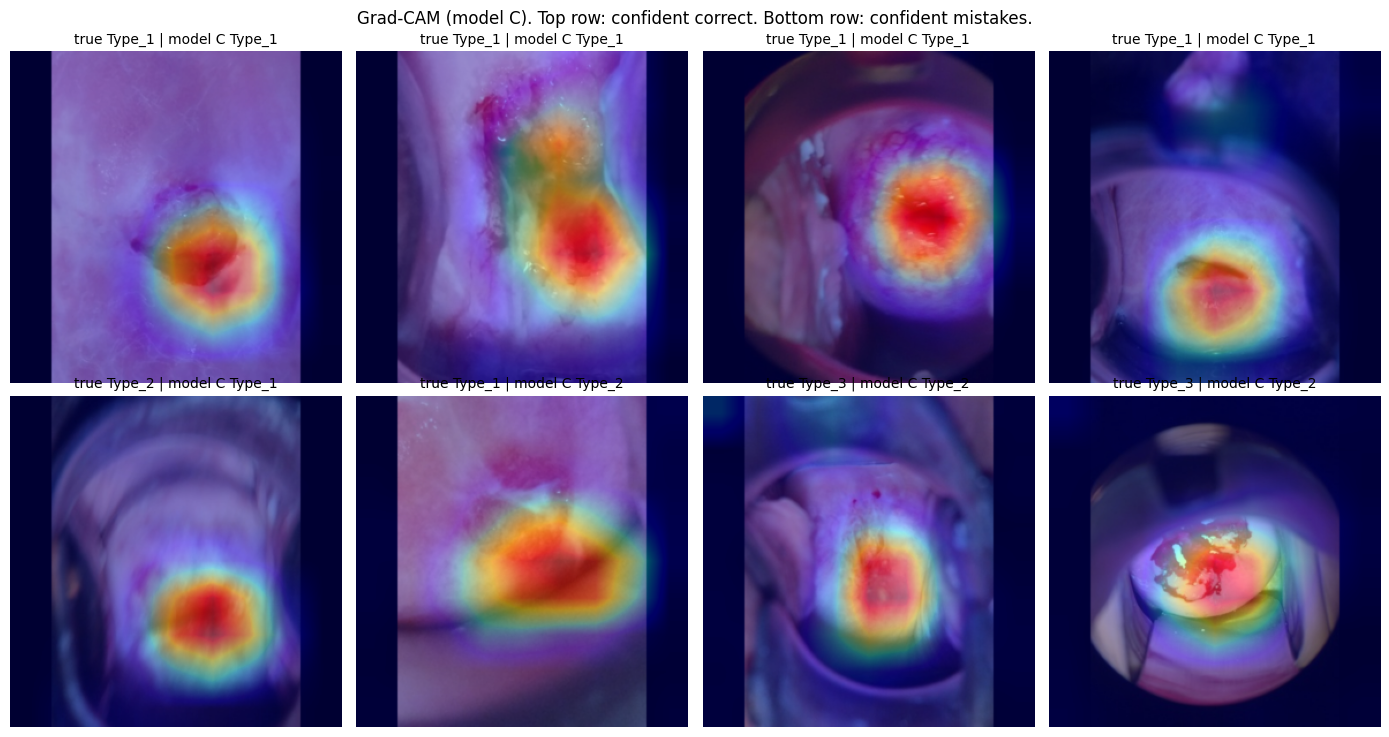

In [16]:
mc = build("efficientnet_b2")
mc.load_state_dict(torch.load(f"{OUT}/e4_b2_288_extra.pt", map_location=dev))
mc.eval()

feats, grads = {}, {}
def fwd(module, inp, out):
    feats["a"] = out
    out.register_hook(lambda g: grads.update(a=g))
hook = mc.features[-1].register_forward_hook(fwd)

def gradcam(x):
    mc.zero_grad()
    out = mc(x)
    cls = int(out.argmax(1))
    out[0, cls].backward()
    w = grads["a"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * feats["a"]).sum(1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), cls

show_tf = T.Compose([PadSquare(), T.Resize((288, 288))])
in_tf = T.Compose([T.ToTensor(), norm])
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), list(best[:4]) + list(worst[:4])):
    with Image.open(va.iloc[i]["path"]) as raw:
        im = show_tf(raw.convert("RGB"))
    cam, cls = gradcam(in_tf(im).unsqueeze(0).to(dev))
    ax.imshow(im); ax.imshow(cam, cmap="jet", alpha=0.4)
    ax.set_title(f"true {classes[Y[i]]} | model C {classes[cls]}", fontsize=10); ax.axis("off")
fig.suptitle("Grad-CAM (model C). Top row: confident correct. Bottom row: confident mistakes.")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_gradcam.png", dpi=150); plt.show()
hook.remove()

Temperature scaling. The "5-fold" row is the honest one (T is fitted on part of the validation set and scored on the rest). Expected: T about 0.80; log loss barely changes (about 0.621 to 0.614); ECE drops (about 0.069 to 0.027); accuracy unchanged.

temperature fitted on all 222: 0.80
before                                 logloss 0.621  ECE 0.069  acc 0.743
after, fitted on all 222 (optimistic)  logloss 0.609  ECE 0.043  acc 0.743
after, 5-fold (honest)                 logloss 0.614  ECE 0.027  acc 0.743


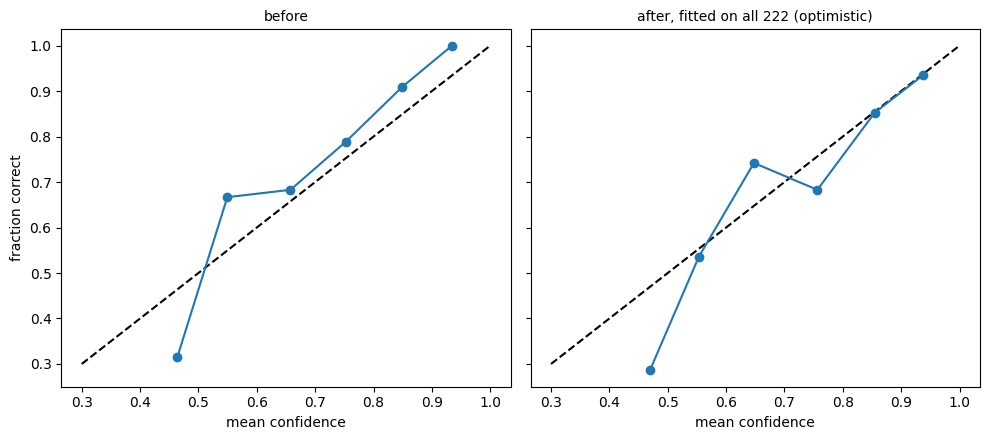

In [17]:
from scipy.optimize import minimize_scalar
from sklearn.model_selection import StratifiedKFold

def fit_T(P, y):
    r = minimize_scalar(lambda t: log_loss(y, apply_T(P, t), labels=L), bounds=(0.3, 3.0), method="bounded")
    return r.x

T_all = fit_T(Pens, Y)
print(f"temperature fitted on all {len(Y)}: {T_all:.2f}")
np.save(f"{OUT}/temperature.npy", np.array([T_all]))

Pcv = np.zeros_like(Pens)
for a, b in StratifiedKFold(5, shuffle=True, random_state=42).split(Pens, Y):
    Pcv[b] = apply_T(Pens[b], fit_T(Pens[a], Y[a]))

rows = [("before", Pens),
        (f"after, fitted on all {len(Y)} (optimistic)", apply_T(Pens, T_all)),
        ("after, 5-fold (honest)", Pcv)]
for name, P in rows:
    print(f"{name:38s} logloss {log_loss(Y, P, labels=L):.3f}  ECE {ece(P, Y):.3f}  acc {accuracy_score(Y, P.argmax(1)):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for a_, (name, P) in zip(ax, rows[:2]):
    cf, ok = P.max(1), (P.argmax(1) == Y)
    edges, xs, ys = np.linspace(0.3, 1, 8), [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (cf > lo) & (cf <= hi)
        if m.sum() >= 5:
            xs.append(cf[m].mean()); ys.append(ok[m].mean())
    a_.plot([0.3, 1], [0.3, 1], "k--"); a_.plot(xs, ys, "o-")
    a_.set_title(name, fontsize=10); a_.set_xlabel("mean confidence")
ax[0].set_ylabel("fraction correct")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_calibration.png", dpi=150); plt.show()

Two checks of the design: (1) class weights on/off, (2) seed-to-seed spread for model C. The spread tells you how large a difference between two runs has to be before it means anything.

In [18]:
model_nw = train("e5_b2_288_noweights", "efficientnet_b2", tr, va, 288, seed=11, lr=2e-4, use_class_weights=False)
Pnw = np.load(f"{OUT}/val_probs_e5_b2_288_noweights.npy")
for name, P in [("C with class weights", probs["C"]), ("C without weights", Pnw)]:
    r = confusion_matrix(Y, P.argmax(1)); rec = r.diagonal() / r.sum(1)
    print(f"{name:22s} logloss {log_loss(Y, P, labels=L):.3f}  acc {accuracy_score(Y, P.argmax(1)):.3f}  recall T1/T2/T3 {rec[0]:.2f}/{rec[1]:.2f}/{rec[2]:.2f}")
del model_nw; torch.cuda.empty_cache()

seed_probs = {11: probs["C"]}
for s in [21, 31]:
    m = train(f"e6_b2_288_seed{s}", "efficientnet_b2", tr, va, 288, seed=s, lr=2e-4)
    seed_probs[s] = np.load(f"{OUT}/val_probs_e6_b2_288_seed{s}.npy")
    del m; torch.cuda.empty_cache()

ll = [log_loss(Y, P, labels=L) for P in seed_probs.values()]
ac = [accuracy_score(Y, P.argmax(1)) for P in seed_probs.values()]
for s, a, b in zip(seed_probs, ll, ac):
    print(f"seed {s}: logloss {a:.3f}  acc {b:.3f}")
print(f"mean +- sd  logloss {np.mean(ll):.3f} +- {np.std(ll, ddof=1):.3f}   acc {np.mean(ac):.3f} +- {np.std(ac, ddof=1):.3f}")
Pseeds = np.mean(list(seed_probs.values()), axis=0)
print(f"average of the 3 seeds  logloss {log_loss(Y, Pseeds, labels=L):.3f}  acc {accuracy_score(Y, Pseeds.argmax(1)):.3f}")

e5_b2_288_noweights: class weights [1.0, 1.0, 1.0]
ep  1 | train 0.932 | val logloss 0.774 acc 0.667 | 53s
ep  2 | train 0.798 | val logloss 0.769 acc 0.658 | 53s
ep  3 | train 0.668 | val logloss 0.755 acc 0.671 | 53s
ep  4 | train 0.568 | val logloss 0.788 acc 0.671 | 53s
ep  5 | train 0.475 | val logloss 0.714 acc 0.676 | 53s
ep  6 | train 0.435 | val logloss 0.793 acc 0.703 | 53s
ep  7 | train 0.397 | val logloss 0.746 acc 0.703 | 53s
ep  8 | train 0.369 | val logloss 0.820 acc 0.685 | 53s
ep  9 | train 0.357 | val logloss 0.781 acc 0.689 | 53s
ep 10 | train 0.345 | val logloss 0.745 acc 0.703 | 53s
early stop
best val logloss: 0.714
C with class weights   logloss 0.713  acc 0.757  recall T1/T2/T3 0.59/0.81/0.75
C without weights      logloss 0.714  acc 0.676  recall T1/T2/T3 0.41/0.77/0.66
e6_b2_288_seed21: class weights [1.9049999713897705, 0.6309999823570251, 1.125]
ep  1 | train 1.005 | val logloss 0.977 acc 0.509 | 53s
ep  2 | train 0.858 | val logloss 0.813 acc 0.617 | 53s
ep

Bootstrap intervals on validation (calibrated ensemble) and a paired test: is the ensemble really better than model C alone? These validation numbers are **optimistic**, because validation also chose the checkpoints, the ensemble and T. The test set (Part 4) is the headline.

In [19]:
T_val = float(np.load(f"{OUT}/temperature.npy")[0])
Pcal = apply_T(Pens, T_val)
print("T =", round(T_val, 2), "| calibrated logloss", round(log_loss(Y, Pcal, labels=L), 3))
print(ci_table(Pcal, Y, metrics, NAMES).to_string(index=False))

rng = np.random.default_rng(42)
d = []
for _ in range(2000):
    i = rng.integers(0, len(Y), len(Y))
    d.append(log_loss(Y[i], Pens[i], labels=L) - log_loss(Y[i], probs["C"][i], labels=L))
lo, hi = np.percentile(d, [2.5, 97.5])
print(f"logloss(ensemble) - logloss(C): {np.mean(d):.3f}  95% CI [{lo:.3f}, {hi:.3f}]")
print("ensemble clearly better" if hi < 0 else "difference not clearly different from zero")

T = 0.8 | calibrated logloss 0.609
      measure  value  ci_low  ci_high
      logloss  0.609   0.516    0.701
     accuracy  0.743   0.689    0.797
Type_1 recall  0.514   0.351    0.679
Type_2 recall  0.838   0.769    0.899
Type_3 recall  0.706   0.597    0.808
    macro AUC  0.882   0.842    0.917
logloss(ensemble) - logloss(C): -0.091  95% CI [-0.194, -0.002]
ensemble clearly better


## Part 4: freeze the pipeline, evaluate on test once

In [20]:
def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()[:16]

final = {
    "models": [
        {"tag": "A", "weights": "e2_b0_extra.pt",     "arch": "efficientnet_b0", "size": 256},
        {"tag": "B", "weights": "e3_b0_384_extra.pt", "arch": "efficientnet_b0", "size": 384},
        {"tag": "C", "weights": "e4_b2_288_extra.pt", "arch": "efficientnet_b2", "size": 288},
    ],
    "combine": "equal mean of softmax probabilities, no flip TTA",
    "temperature": float(np.load(f"{OUT}/temperature.npy")[0]),
    "classes": classes,
}
for s in final["models"]:
    s["sha256"] = sha(f"{OUT}/{s['weights']}")
    print(s["tag"], s["weights"], s["sha256"])
json.dump(final, open(f"{OUT}/final_pipeline.json", "w"), indent=2)
print("T =", round(final["temperature"], 3))

def predict_final(df, cfg=final):
    P = []
    for s in cfg["models"]:
        m = build(s["arch"])
        m.load_state_dict(torch.load(f"{OUT}/{s['weights']}", map_location=dev))
        p, y = predict(m, loader(df, s["size"]))
        P.append(p)
        del m; torch.cuda.empty_cache()
    Pm = np.mean(P, axis=0)
    return apply_T(Pm, cfg["temperature"]), Pm, y

A e2_b0_extra.pt 6e5bfc81829106dc
B e3_b0_384_extra.pt 7e9b34e372b0bece
C e4_b2_288_extra.pt ec76de1f0c7f5a05
T = 0.803


Freeze check: reload the weights from disk, confirm they match the saved hashes, and confirm the reloaded pipeline reproduces the validation ensemble. Expected: `max diff` below 0.001 and `test already evaluated: False` on the first run.

In [21]:
fin = json.load(open(f"{OUT}/final_pipeline.json"))
for s in fin["models"]:
    assert sha(f"{OUT}/{s['weights']}") == s["sha256"], f"weights changed: {s['weights']}"

Pc_chk, Pm_chk, Y_chk = predict_final(va)
print("max diff vs saved ensemble:", float(np.abs(Pm_chk - Pens).max()))
assert np.abs(Pm_chk - Pens).max() < 1e-3, "pipeline does not reproduce the validation ensemble"
print(f"before T: logloss {log_loss(Y_chk, Pm_chk, labels=L):.3f} acc {accuracy_score(Y_chk, Pm_chk.argmax(1)):.3f}")
print(f"after  T: logloss {log_loss(Y_chk, Pc_chk, labels=L):.3f} acc {accuracy_score(Y_chk, Pc_chk.argmax(1)):.3f}")
print("test images:", len(te), "| test already evaluated:", os.path.exists(f"{OUT}/test_probs_final.npy"))

max diff vs saved ensemble: 0.0
before T: logloss 0.621 acc 0.743
after  T: logloss 0.609 acc 0.743
test images: 222 | test already evaluated: False


**Test evaluation. Run once.** The guard stops a second run, so the test set is never used to make another choice.

before T         logloss 0.583  ECE 0.077  acc 0.752
after T (final)  logloss 0.560  ECE 0.058  acc 0.752
              precision    recall  f1-score   support

      Type_1      0.622     0.605     0.613        38
      Type_2      0.762     0.795     0.778       117
      Type_3      0.810     0.761     0.785        67

    accuracy                          0.752       222
   macro avg      0.731     0.720     0.725       222
weighted avg      0.752     0.752     0.752       222

[[23 13  2]
 [14 93 10]
 [ 0 16 51]]
      measure  value  ci_low  ci_high
      logloss  0.560   0.473    0.659
     accuracy  0.752   0.694    0.806
Type_1 recall  0.605   0.454    0.756
Type_2 recall  0.795   0.717    0.865
Type_3 recall  0.761   0.648    0.857
    macro AUC  0.895   0.855    0.931


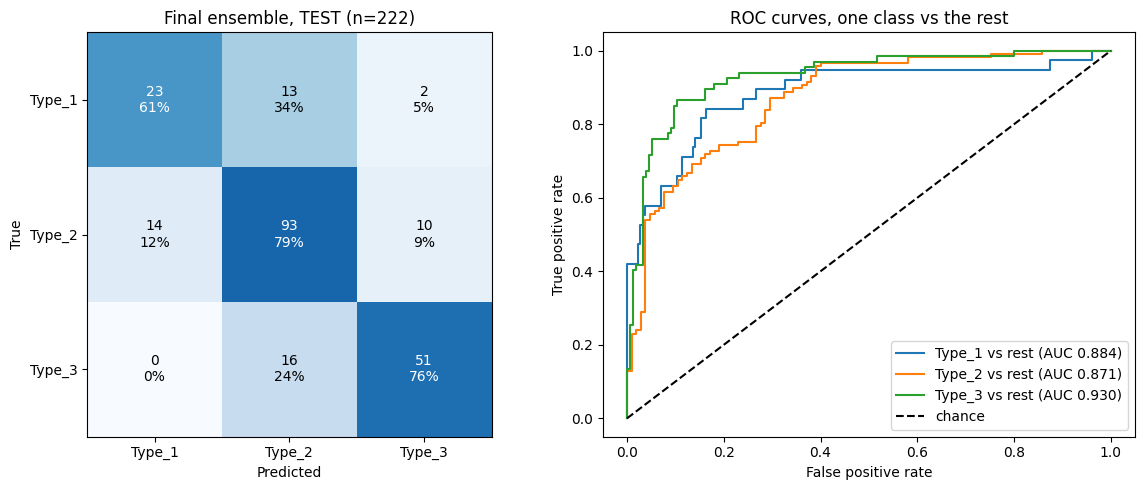

macro AUC: 0.895


In [22]:
assert not os.path.exists(f"{OUT}/test_probs_final.npy"), "Test already evaluated. Load the saved files instead of running again."

Pt_cal, Pt_raw, Yt = predict_final(te)
np.save(f"{OUT}/test_probs_final.npy", Pt_cal)
np.save(f"{OUT}/test_probs_raw.npy", Pt_raw)
np.save(f"{OUT}/test_labels.npy", Yt)
te[["file"]].to_csv(f"{OUT}/test_files.csv", index=False)   # row order of the saved test arrays

for name, P in [("before T", Pt_raw), ("after T (final)", Pt_cal)]:
    print(f"{name:16s} logloss {log_loss(Yt, P, labels=L):.3f}  ECE {ece(P, Yt):.3f}  acc {accuracy_score(Yt, P.argmax(1)):.3f}")
print(classification_report(Yt, Pt_cal.argmax(1), target_names=classes, digits=3))
print(confusion_matrix(Yt, Pt_cal.argmax(1)))
print(ci_table(Pt_cal, Yt, metrics, NAMES).to_string(index=False))
plot_cm_roc(Pt_cal, Yt, f"Final ensemble, TEST (n={len(Yt)})", "fig_test_confusion_roc.png")

## Part 5: extra evaluation

These steps only read saved files, so they do not touch the models or the test set again.

**Step 46: reference baseline and more metrics.** What does the test log loss mean compared with a model that ignores the image? Also measures suited to imbalanced, ordered classes (Type_1 < Type_2 < Type_3), each with a 95% bootstrap interval.

In [23]:
from sklearn.metrics import balanced_accuracy_score, f1_score, matthews_corrcoef, cohen_kappa_score

Pt = np.load(f"{OUT}/test_probs_final.npy")
Yt = np.load(f"{OUT}/test_labels.npy")
prior = np.load(f"{OUT}/train_prior.npy")
Pprior = np.tile(prior, (len(Yt), 1))
print(f"prior only   logloss {log_loss(Yt, Pprior, labels=L):.3f}  acc {accuracy_score(Yt, Pprior.argmax(1)):.3f}   (no image information)")
print(f"final model  logloss {log_loss(Yt, Pt, labels=L):.3f}  acc {accuracy_score(Yt, Pt.argmax(1)):.3f}")

def brier(P, y):
    return float(np.mean(np.sum((P - np.eye(3)[y]) ** 2, axis=1)))

def more(P, y):
    p = P.argmax(1)
    return [brier(P, y), balanced_accuracy_score(y, p), f1_score(y, p, average="macro"),
            matthews_corrcoef(y, p), cohen_kappa_score(y, p), cohen_kappa_score(y, p, weights="quadratic")]

extra1 = ci_table(Pt, Yt, more, ["Brier score", "balanced accuracy", "macro F1", "MCC", "Cohen kappa", "quadratic kappa"])
print(extra1.to_string(index=False))
extra1.to_csv(f"{OUT}/extra_metrics.csv", index=False)

prior only   logloss 1.001  acc 0.527   (no image information)
final model  logloss 0.560  acc 0.752
          measure  value  ci_low  ci_high
      Brier score  0.319   0.265    0.378
balanced accuracy  0.720   0.650    0.783
         macro F1  0.725   0.656    0.783
              MCC  0.585   0.481    0.672
      Cohen kappa  0.584   0.479    0.671
  quadratic kappa  0.692   0.601    0.766


**Step 47: how bad are the mistakes?** Type_1 mistaken for Type_3 (or the reverse) is worse than Type_1 mistaken for Type_2. Also sensitivity, specificity and precision per class.

In [24]:
pred = Pt.argmax(1)
cm = confusion_matrix(Yt, pred, labels=L)
gap = np.abs(pred - Yt)
print(f"errors: {int((gap > 0).sum())} of {len(Yt)} | one step off: {int((gap == 1).sum())} | two steps off (Type_1 <-> Type_3): {int((gap == 2).sum())}")

tab = []
for k, c in enumerate(classes):
    tp = cm[k, k]; fn = cm[k].sum() - tp
    fp = cm[:, k].sum() - tp; tn = cm.sum() - tp - fn - fp
    tab.append(dict(cls=c, sensitivity=tp / (tp + fn), specificity=tn / (tn + fp), precision=tp / (tp + fp)))
print(pd.DataFrame(tab).round(3).to_string(index=False))

errors: 55 of 222 | one step off: 53 | two steps off (Type_1 <-> Type_3): 2
   cls  sensitivity  specificity  precision
Type_1        0.605        0.924      0.622
Type_2        0.795        0.724      0.762
Type_3        0.761        0.923      0.810


**Step 48: can the model tell when it is unsure?** Keep only the most confident predictions and see whether accuracy rises. Useful for a screening tool where unsure cases go to a human.

confidence separates correct from wrong (AUC): 0.799  (0.5 = no use)
coverage | kept | accuracy on kept | lowest confidence kept
    100% |  222 | 0.752 | 0.42
     90% |  200 | 0.795 | 0.52
     80% |  178 | 0.837 | 0.58
     70% |  155 | 0.871 | 0.65
     60% |  133 | 0.917 | 0.72
     50% |  111 | 0.919 | 0.78


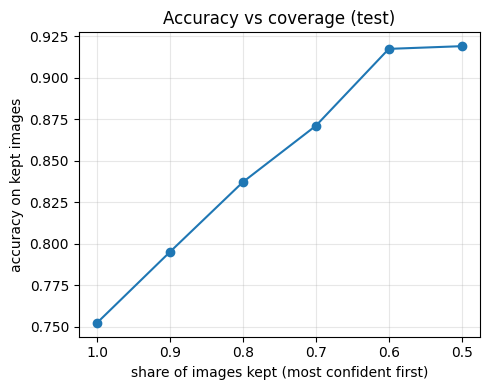

In [25]:
conf, ok = Pt.max(1), (Pt.argmax(1) == Yt)
order = np.argsort(-conf)
print(f"confidence separates correct from wrong (AUC): {roc_auc_score(ok, conf):.3f}  (0.5 = no use)")

cov, acc_at = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5], []
print("coverage | kept | accuracy on kept | lowest confidence kept")
for f in cov:
    k = int(round(f * len(Yt)))
    idx = order[:k]
    acc_at.append(ok[idx].mean())
    print(f"{f:8.0%} | {k:4d} | {ok[idx].mean():.3f} | {conf[idx[-1]]:.2f}")

plt.figure(figsize=(5, 4))
plt.plot(cov, acc_at, "o-")
plt.xlabel("share of images kept (most confident first)"); plt.ylabel("accuracy on kept images")
plt.title("Accuracy vs coverage (test)"); plt.gca().invert_xaxis(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_selective.png", dpi=150); plt.show()

**Step 49 (new): leakage sensitivity.** The split is by image, not by patient, because the dataset has no patient IDs. Photos of the same cervix in train and test would make the test score too good. Here each test image is tagged with its distance to the nearest training image (from Part 2), and accuracy is compared for "close to a training image" vs "far from all training images". If the far group scores clearly lower, the headline number is inflated. With a small group, treat the comparison as a rough signal, not a proof.

In [26]:
leak = pd.read_csv(f"{OUT}/leak_table.csv")
tfiles = pd.read_csv(f"{OUT}/test_files.csv")
d_test = tfiles.merge(leak[leak["split"] == "test"], on="file", how="left")["d_train"].values
assert not np.isnan(d_test).any(), "some test files are missing from leak_table.csv"
ok = (Pt.argmax(1) == Yt)

print("threshold | near: n, accuracy | far: n, accuracy, logloss")
for thr in [0, 4, 8, 10]:
    near = d_test <= thr
    far = ~near
    a_near = ok[near].mean() if near.any() else float("nan")
    ll_far = log_loss(Yt[far], Pt[far], labels=L) if far.sum() > 10 else float("nan")
    print(f"<= {thr:2d}     | {near.sum():3d}, {a_near:.3f}     | {far.sum():3d}, {ok[far].mean():.3f}, {ll_far:.3f}")

threshold | near: n, accuracy | far: n, accuracy, logloss
<=  0     |   0, nan     | 222, 0.752, 0.560
<=  4     |   0, nan     | 222, 0.752, 0.560
<=  8     |   0, nan     | 222, 0.752, 0.560
<= 10     |   7, 0.857     | 215, 0.749, 0.565


## Part 6: export and report

`predict.py` resizes every image so its longest side is 384 px before anything else, exactly like Part 1 did for the training images. Without this step the saved script would see full-size photos that the models never saw.

In [27]:
SCRIPT = '''"""Predict cervix type (Type_1/2/3) for a folder of images with the frozen A+B+C ensemble."""
import argparse, json, os, glob
import numpy as np, pandas as pd, torch, torch.nn as nn
import torchvision.transforms as T
from PIL import Image
from torchvision import models

class PadSquare:
    def __call__(self, im):
        w, h = im.size; s = max(w, h)
        c = Image.new("RGB", (s, s), (0, 0, 0)); c.paste(im, ((s - w) // 2, (s - h) // 2)); return c

NORM = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
ARCH = {"efficientnet_b0": models.efficientnet_b0, "efficientnet_b2": models.efficientnet_b2}
PRE_SIZE = 384   # training images were shrunk to a longest side of 384 px before the models saw them

def load_image(path):
    with Image.open(path) as im:
        im = im.convert("RGB")
        im.thumbnail((PRE_SIZE, PRE_SIZE))
        return im.copy()

def build(arch, dev):
    m = ARCH[arch](weights=None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 3)
    return m.to(dev)

def apply_T(P, t):
    z = np.log(np.clip(P, 1e-8, 1)) / t
    z -= z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--images", required=True)
    ap.add_argument("--pipeline", default="final_pipeline.json")
    ap.add_argument("--weights_dir", default=".")
    ap.add_argument("--out", default="predictions.csv")
    a = ap.parse_args()
    cfg = json.load(open(a.pipeline))
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    exts = (".jpg", ".jpeg", ".png")
    files = sorted(f for f in glob.glob(os.path.join(a.images, "**", "*"), recursive=True) if f.lower().endswith(exts))
    assert files, "no images found"
    P = []
    for s in cfg["models"]:
        m = build(s["arch"], dev)
        m.load_state_dict(torch.load(os.path.join(a.weights_dir, s["weights"]), map_location=dev))
        m.eval()
        tf = T.Compose([PadSquare(), T.Resize((s["size"], s["size"])), T.ToTensor(), NORM])
        out = []
        with torch.no_grad():
            for i in range(0, len(files), 32):
                x = torch.stack([tf(load_image(f)) for f in files[i:i+32]]).to(dev)
                with torch.autocast(dev, enabled=(dev == "cuda")):
                    out.append(torch.softmax(m(x).float(), 1).cpu().numpy())
        P.append(np.concatenate(out))
    Pf = apply_T(np.mean(P, axis=0), cfg["temperature"])
    df = pd.DataFrame(Pf, columns=[f"prob_{c}" for c in cfg["classes"]])
    df.insert(0, "file", files)
    df["prediction"] = [cfg["classes"][i] for i in Pf.argmax(1)]
    df["confidence"] = Pf.max(1).round(4)
    df.to_csv(a.out, index=False)
    print(df["prediction"].value_counts().to_dict(), "->", a.out)

if __name__ == "__main__":
    main()
'''
open(f"{OUT}/predict.py", "w").write(SCRIPT)
print("saved predict.py,", len(SCRIPT.splitlines()), "lines")

saved predict.py, 68 lines


Check that the script gives the same probabilities as the notebook pipeline on 24 validation images. Expected: `max diff` well below 0.01 and `predict.py verified`. (These images are already 384 px, so this checks the script logic, not the resize step.)

In [28]:
d = f"{OUT}/chk_imgs"
os.makedirs(d, exist_ok=True)
for i, p in enumerate(va["path"].head(24)):
    shutil.copy(p, f"{d}/{i:02d}_{os.path.basename(p)}")

r = subprocess.run([sys.executable, f"{OUT}/predict.py", "--images", d, "--pipeline", f"{OUT}/final_pipeline.json",
                    "--weights_dir", OUT, "--out", f"{OUT}/chk_pred.csv"], capture_output=True, text=True)
print(r.stdout, r.stderr[-400:])
got = pd.read_csv(f"{OUT}/chk_pred.csv")[[f"prob_{c}" for c in classes]].values
print("max diff vs predict_final:", float(np.abs(got - Pc_chk[:24]).max()))
assert np.abs(got - Pc_chk[:24]).max() < 1e-2, "script does not match the notebook pipeline"
shutil.rmtree(d); os.remove(f"{OUT}/chk_pred.csv")
print("predict.py verified")

{'Type_1': 11, 'Type_2': 10, 'Type_3': 3} -> /kaggle/working/chk_pred.csv
 
max diff vs predict_final: 0.00069629847427366
predict.py verified


Results table for the report. The baseline row shows what the extra images added; the validation rows are optimistic (see Part 3), the test rows are the headline.

In [29]:
Yv = np.load(f"{OUT}/val_labels.npy")
Yt = np.load(f"{OUT}/test_labels.npy")
ld = lambda f: np.load(f"{OUT}/{f}.npy")
T_fin = float(np.load(f"{OUT}/temperature.npy")[0])

entries = [
    ("Baseline: B0 256 px, original images only", ld("val_probs_e1_baseline"), Yv, "validation"),
    ("Run A: B0 256 px",             ld("val_probs_e2_b0_extra"),      Yv, "validation"),
    ("Run B: B0 384 px",             ld("val_probs_e3_b0_384_extra"),  Yv, "validation"),
    ("Run C: B2 288 px (seed 11)",   ld("val_probs_e4_b2_288_extra"),  Yv, "validation"),
    ("Run C, seed 21",               ld("val_probs_e6_b2_288_seed21"), Yv, "validation"),
    ("Run C, seed 31",               ld("val_probs_e6_b2_288_seed31"), Yv, "validation"),
    ("Run C without class weights",  ld("val_probs_e5_b2_288_noweights"),  Yv, "validation"),
    ("Ensemble A+B+C",               ld("val_probs_ens"),              Yv, "validation"),
    ("Ensemble A+B+C + T (final)",   apply_T(ld("val_probs_ens"), T_fin), Yv, "validation"),
    ("Ensemble A+B+C",               ld("test_probs_raw"),             Yt, "test"),
    ("Ensemble A+B+C + T (final)",   ld("test_probs_final"),           Yt, "test"),
]
rows = []
for name, P, y, split in entries:
    m = metrics(P, y)
    rows.append(dict(model=name, split=split, logloss=m[0], accuracy=m[1],
                     t1_recall=m[2], t2_recall=m[3], t3_recall=m[4], macro_auc=m[5]))
res = pd.DataFrame(rows).round(3)
res.to_csv(f"{OUT}/results_table.csv", index=False)
print(res.to_string(index=False))

                                    model      split  logloss  accuracy  t1_recall  t2_recall  t3_recall  macro_auc
Baseline: B0 256 px, original images only validation    0.861     0.599      0.378      0.598      0.721      0.752
                         Run A: B0 256 px validation    0.756     0.694      0.541      0.718      0.735      0.833
                         Run B: B0 384 px validation    0.740     0.653      0.351      0.846      0.485      0.822
               Run C: B2 288 px (seed 11) validation    0.713     0.757      0.595      0.812      0.750      0.863
                           Run C, seed 21 validation    0.708     0.734      0.568      0.803      0.706      0.851
                           Run C, seed 31 validation    0.711     0.712      0.649      0.692      0.779      0.853
              Run C without class weights validation    0.714     0.676      0.405      0.769      0.662      0.841
                           Ensemble A+B+C validation    0.621     0.743 

In [30]:
try:
    import docx
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-docx"], check=True)
    import docx
from docx import Document
from docx.shared import Inches

def add_table(doc, header, rows):
    t = doc.add_table(rows=1, cols=len(header))
    t.style = "Light Grid Accent 1"
    for i, h in enumerate(header):
        t.rows[0].cells[i].text = h
    for r in rows:
        c = t.add_row().cells
        for i, v in enumerate(r):
            c[i].text = str(v)

Pt_f = np.load(f"{OUT}/test_probs_final.npy")
test_ci = ci_table(Pt_f, Yt, metrics, NAMES)
test_rows = [[r.measure, f"{r.value:.3f}", f"{r.ci_low:.3f} to {r.ci_high:.3f}"] for r in test_ci.itertuples()]

doc = Document()
doc.add_heading("Results: cervix type classification (EfficientNet ensemble)", 1)
doc.add_paragraph("All numbers are computed from the saved probability files. The validation and test sets have 222 images "
                  "each and contain original competition images only. Intervals are 95% bootstrap intervals (2,000 resamples). "
                  "Validation numbers are optimistic because validation also selected checkpoints, the ensemble and the temperature.")
doc.add_heading("Model comparison", 2)
add_table(doc, list(res.columns), res.astype(str).values.tolist())
doc.add_heading("Final test results (evaluated once)", 2)
add_table(doc, ["Measure", "Value", "95% interval"], test_rows)
doc.add_paragraph("Test confusion matrix (rows true, columns predicted: Type_1, Type_2, Type_3): "
                  + str(confusion_matrix(Yt, Pt_f.argmax(1)).tolist()))

doc.add_heading("Figures", 2)
for fn, cap in [("fig_test_confusion_roc.png", "Final ensemble on the test set: confusion matrix and ROC curves."),
                ("fig_confusion_roc.png",      "Ensemble on the validation set: confusion matrix and ROC curves."),
                ("fig_calibration.png",        "Reliability diagrams before and after temperature scaling (validation)."),
                ("fig_gradcam.png",            "Grad-CAM for model C. Top row: confident correct. Bottom row: confident mistakes."),
                ("fig_confident_mistakes.png", "Most confident mistakes on the validation set."),
                ("fig_confident_correct.png",  "Most confident correct predictions on the validation set."),
                ("fig_selective.png",          "Accuracy vs coverage on the test set.")]:
    path = f"{OUT}/{fn}"
    if os.path.exists(path):
        doc.add_picture(path, width=Inches(6))
        doc.add_paragraph(cap).runs[0].italic = True
    else:
        print("missing figure, skipped:", fn)
doc.save(f"{OUT}/report_results_section.docx")
print("saved report_results_section.docx")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 5.6 MB/s eta 0:00:00
saved report_results_section.docx
